# Stage 9: Cardiac Readmission Risk Model
**Project:** Hospital Care Quality & Efficiency Analytics
**Data:** the validated mart (`mart.fact_episode` and dimensions), plus `staging.episodes` and `staging.conditions` for patient history

**Goal:** score every cardiac patient's risk of an unplanned readmission within 30 days, so the
counterfactual analysis can target follow-up at the highest-risk patients first.

**Decisions made before modelling**

| Decision | Choice | Why |
|---|---|---|
| Who is scored | Cardiac index episodes, 2017 to 2025 | Cardiac patients hold 83% of readmissions |
| Split | Train on 2017 to 2022, test on 2023 to 2025 | Mimics real use (past data scores future patients), and the test years are the success test period |
| Models | Logistic regression (baseline) vs three challengers: LightGBM, XGBoost and random forest | The more complex models have to earn their place |
| Winner | The challenger with the highest cross-validated AUC on the training years, if it beats logistic regression by at least 0.01; otherwise logistic regression | Chosen on training data only, so the test years stay untouched |
| Tuning | Default settings for the four-model comparison; then all four models are tuned with Optuna on the same budget (logistic regression and random forest first, then XGBoost and LightGBM) | A fair first comparison, then equal tuning effort for every model |
| Incumbent rule | A model tuned later replaces the current champion only if it beats it by at least 0.01 AUC on fresh folds | So the champion cannot change on a difference that is just noise |
| Calibration | The tuned champion is calibrated with Platt scaling (sigmoid) | The counterfactuals need probabilities that match actual rates; sigmoid keeps the ranking unchanged |
| Class balance | No oversampling or reweighting | The counterfactuals need calibrated probabilities |
| Features | Only what is known at discharge | So the model never sees the future |

| Section | Question |
|---|---|
| 1 | Build the modelling table |
| 2 | Which features relate to readmission? |
| 3 | Split the data |
| 4 | Baseline: logistic regression |
| 5 | Challengers: LightGBM, XGBoost and random forest |
| 6 | Choose the champion |
| 6b | Fine-tune all four models and calibrate the champion |
| 7 | How well does each model work on the test years? |
| 8 | What drives the risk? |
| 9 | Save the risk scores |
| 10 | Summary |

## 0. Setup

In [1]:
%matplotlib inline
import sys
from math import ceil
from pathlib import Path

import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from lightgbm import LGBMClassifier
    from xgboost import XGBClassifier
except ImportError as err:
    raise ImportError("LightGBM or XGBoost is not installed. In the (base) terminal run "
                      "'pip install lightgbm xgboost', then restart the kernel.") from err

# Find the project root (the folder containing .env) and import config.py from python/
root = Path.cwd()
while not (root / ".env").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "python"))
from config import get_engine

engine = get_engine()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 2026            # same seed as the Synthea generation, for reproducible results
TRAIN_END_YEAR = 2022  # train on 2017-2022, test on 2023-2025


def q(sql):
    """Run a SQL query in PostgreSQL and return the (small) result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


q("SELECT current_database() AS database")

,database
0,hospital_analytics


## 1. Build the modelling table
One row per cardiac index episode (episodes that can be followed by a readmission), with the target
and every feature. The two history features are counted **as of each admission date**, so nothing
from after the admission leaks in:

* **Prior admissions (12 months):** the patient's episodes admitted in the 365 days before this admission
* **Active conditions:** the patient's diagnoses that started on or before the admission date and had not stopped by then

In [2]:
MODEL_SQL = """
    WITH cohort AS (
        SELECT
            f.episode_id,
            f.patient_id,
            f.admit_date,
            EXTRACT(YEAR FROM f.admit_date)::int  AS admit_year,
            -- a blank flag means there was no later admission at all, so not readmitted
            COALESCE(f.is_readmitted_30d, 0)      AS readmitted,
            -- features known at discharge
            f.age_at_admission,
            p.gender,
            py.payer_name,
            d.diagnosis_label,
            f.los_days,
            f.stays_in_episode,
            dt.month_short                        AS admit_month,
            dt.day_name                           AS admit_weekday
        FROM mart.fact_episode f
        JOIN mart.dim_diagnosis d  ON d.diagnosis_key = f.diagnosis_key
        JOIN mart.dim_patient   p  ON p.patient_id   = f.patient_id
        JOIN mart.dim_payer     py ON py.payer_id    = f.payer_id
        JOIN mart.dim_date      dt ON dt.date        = f.admit_date
        WHERE d.diagnosis_group = 'Cardiac'
          AND f.is_index_eligible = 1
    )
    SELECT c.*,
           pa.prior_admissions_12m,
           ac.active_conditions
    FROM cohort c
    CROSS JOIN LATERAL (
        SELECT COUNT(*) AS prior_admissions_12m
        FROM staging.episodes e
        WHERE e.patient_id = c.patient_id
          AND e.admit_date >= c.admit_date - 365
          AND e.admit_date <  c.admit_date
    ) pa
    CROSS JOIN LATERAL (
        SELECT COUNT(*) AS active_conditions
        FROM staging.conditions sc
        WHERE sc.patient_id = c.patient_id
          AND sc.start_date <= c.admit_date
          AND (sc.stop_date IS NULL OR sc.stop_date > c.admit_date)
    ) ac
    ORDER BY c.admit_date, c.episode_id
"""

df = q(MODEL_SQL)
df["period"] = np.where(df["admit_year"] <= TRAIN_END_YEAR, "1. train 2017-2022", "2. test 2023-2025")

# The cohort must match the validated pipeline: 6,777 cardiac index episodes with 528 readmissions,
# and every episode must have a target value
assert df["readmitted"].notna().all(), "The readmission flag has blank values"
assert len(df) == 6777 and df["readmitted"].sum() == 528, "Cohort does not match the validated pipeline"

summary = df.groupby("period").agg(episodes=("episode_id", "count"), readmissions=("readmitted", "sum"))
summary["rate_pct"] = (100 * summary["readmissions"] / summary["episodes"]).round(2)
summary

,episodes,readmissions,rate_pct
period,,,
1. train 2017-2022,4273,341,7.98
2. test 2023-2025,2504,187,7.47


**Interpretation:** The cohort matches the validated pipeline exactly: 6,777 cardiac index episodes with 528 readmissions. The training years hold 4,273 episodes and 341 readmissions (7.98%), and the test years hold 2,504 episodes and 187 readmissions (7.47%). The two periods have similar readmission rates, so a model trained on the earlier years is being tested on a comparable population, and 341 readmissions is enough to fit a model with a modest number of features.

**Missing values check.** Logistic regression cannot use blank values, so any gaps are listed here and
filled inside the model pipeline (median for numbers, "Unknown" for categories).

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("No missing values in the modelling table")
else:
    print("Missing values by column:")
    print(missing.to_string())
    print(f"\nEpisodes with at least one missing value: {df.isna().any(axis=1).sum():,} of {len(df):,}")

No missing values in the modelling table


**Interpretation:** No column has blank values, so the imputation step in the pipeline has nothing to fill. It stays in place as a safeguard in case future data has gaps.

## 2. Which features relate to readmission?
A quick look on the **training years only**, so the test years stay unseen.

In [4]:
train_view = df[df["admit_year"] <= TRAIN_END_YEAR]


def rate_by(column, data=train_view):
    """Readmission rate for each value (or band) of one feature."""
    out = data.groupby(column, observed=True).agg(episodes=("readmitted", "size"),
                                                  readmissions=("readmitted", "sum"))
    out["rate_pct"] = (100 * out["readmissions"] / out["episodes"]).round(2)
    return out


rate_by("diagnosis_label").sort_values("rate_pct", ascending=False)

,episodes,readmissions,rate_pct
diagnosis_label,,,
Aortic valve regurgitation,143,22,15.38
Abnormal findings diagnostic imaging heart+coronary circulat,601,72,11.98
History of coronary artery bypass grafting,1205,133,11.04
Aortic valve stenosis,330,33,10.00
Chronic congestive heart failure,1012,58,5.73
Acute non-ST segment elevation myocardial infarction,543,20,3.68
Preinfarction syndrome,64,2,3.12
Acute ST segment elevation myocardial infarction,375,1,0.27


**Interpretation:** The specific cardiac condition makes a large difference. Readmission rates range from 15.4% for aortic valve regurgitation and 12.0% for abnormal heart imaging down to 0.3% for STEMI heart attacks (1 readmission in 375 episodes). Patients on the bypass surgery and valve pathways come back most often, while acute heart attacks rarely lead to a readmission. Condition is likely to be the strongest feature in any model.

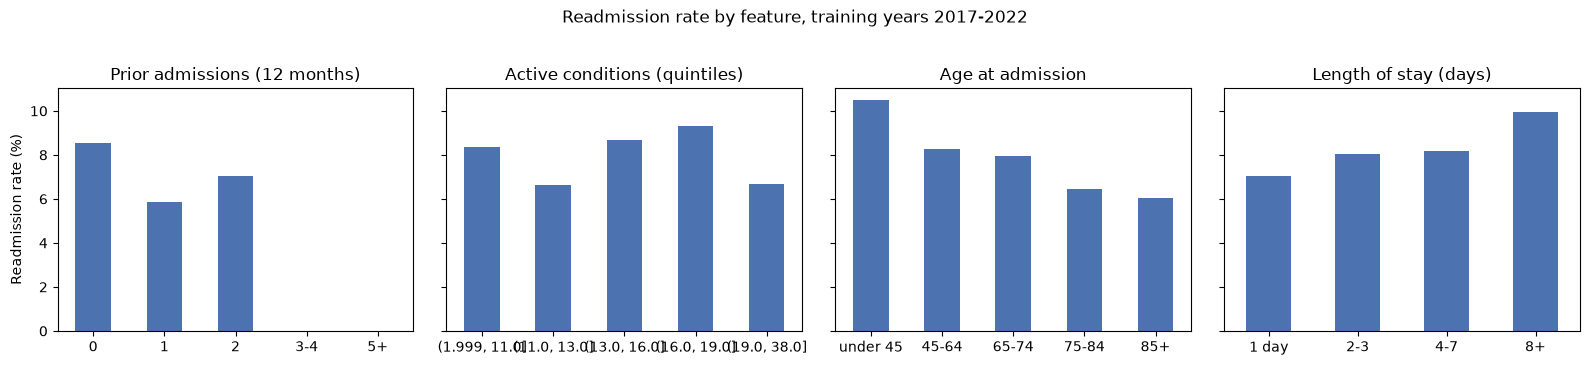

In [5]:
banded = train_view.assign(
    prior_admissions_band=pd.cut(train_view["prior_admissions_12m"], [-1, 0, 1, 2, 4, 1_000],
                                 labels=["0", "1", "2", "3-4", "5+"]),
    active_conditions_band=pd.qcut(train_view["active_conditions"], 5, duplicates="drop"),
    age_band=pd.cut(train_view["age_at_admission"], [0, 44, 64, 74, 84, 200],
                    labels=["under 45", "45-64", "65-74", "75-84", "85+"]),
    los_band=pd.cut(train_view["los_days"], [0, 1, 3, 7, 1_000], labels=["1 day", "2-3", "4-7", "8+"]),
)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (column, title) in zip(axes, [("prior_admissions_band", "Prior admissions (12 months)"),
                                      ("active_conditions_band", "Active conditions (quintiles)"),
                                      ("age_band", "Age at admission"),
                                      ("los_band", "Length of stay (days)")]):
    rate_by(column, banded)["rate_pct"].plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("Readmission rate (%)")
plt.suptitle("Readmission rate by feature, training years 2017-2022", y=1.03)
plt.tight_layout(); plt.show()

**Interpretation:** The other features show much weaker or unexpected patterns. Readmission rates do not rise with prior admissions (8.5% with none, 5.9% with one, 7.0% with two; the 3-4 and 5+ bands show no readmissions or episodes at all), and active conditions show no clear trend across quintiles. Risk falls with age, from 10.5% under 45 to 6.0% at 85 and over, which is the opposite of what real hospitals see and most likely reflects case mix: younger cardiac patients here are more often on the high-risk valve and bypass pathways. Longer stays carry somewhat more risk (7.0% for one day, 9.9% for eight days or more). In real hospitals, prior admissions and comorbidities are among the strongest readmission predictors; in this synthetic data, readmissions follow Synthea's care pathways rather than patient history, which limits how well any model can rank patients.

## 3. Split the data
Train on 2017 to 2022 and test on 2023 to 2025. The test years are never used to fit or choose a model.

In [6]:
NUMERIC = ["age_at_admission", "los_days", "stays_in_episode", "prior_admissions_12m", "active_conditions"]
CATEGORICAL = ["gender", "payer_name", "diagnosis_label", "admit_month", "admit_weekday"]
FEATURES = NUMERIC + CATEGORICAL

train = df[df["admit_year"] <= TRAIN_END_YEAR]
test = df[df["admit_year"] > TRAIN_END_YEAR]
X_train, y_train = train[FEATURES], train["readmitted"]
X_test, y_test = test[FEATURES], test["readmitted"]

print(f"Train: {len(train):,} episodes, {y_train.sum()} readmissions ({y_train.mean():.2%})")
print(f"Test:  {len(test):,} episodes, {y_test.sum()} readmissions ({y_test.mean():.2%})")

Train: 4,273 episodes, 341 readmissions (7.98%)
Test:  2,504 episodes, 187 readmissions (7.47%)


## 4. Baseline: logistic regression
Any blanks are filled first (median for numbers, "Unknown" for categories). Numeric features are then
standardised and categories are one-hot encoded. A grid search picks the
regularisation strength `C` by cross-validated AUC inside the training years. Model quality is then measured
with an outer 5-fold cross-validation, also on the training years only.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def preprocessor(scale_numeric):
    """Fill any blanks, then scale numbers (logistic regression only) and one-hot encode categories."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    categorical_steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), NUMERIC),
        ("cat", Pipeline(categorical_steps), CATEGORICAL),
    ])


logreg = GridSearchCV(
    Pipeline([
        ("prep", preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(max_iter=5000)),
    ]),
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    cv=cv, scoring="roc_auc",
)

lr_cv = cross_val_score(logreg, X_train, y_train, cv=cv, scoring="roc_auc")
logreg.fit(X_train, y_train)
print(f"Logistic regression, cross-validated AUC on 2017-2022: {lr_cv.mean():.3f} (+/- {lr_cv.std():.3f})")
print(f"Chosen regularisation strength C = {logreg.best_params_['model__C']}")

Logistic regression, cross-validated AUC on 2017-2022: 0.640 (+/- 0.025)
Chosen regularisation strength C = 10


## 5. Challengers: LightGBM, XGBoost and random forest
Tree-based models can pick up interactions (for example age combined with condition) that a linear model
misses. All three use sensible, deliberately conservative settings rather than tuned ones, because there are
only about 340 readmissions to learn from. Fine-tuning is saved for whichever model wins.

* **LightGBM** and **XGBoost** are both gradient boosting: many small trees, each correcting the last
* **Random forest** averages many independent deep-ish trees, a different way of combining trees

Each one is scored with the same outer 5-fold cross-validation on the training years as the baseline.

In [8]:
def cv_and_fit(name, model):
    """Cross-validated AUC on the training years, then a final fit on all training years."""
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    print(f"{name:<20} cross-validated AUC on 2017-2022: {scores.mean():.3f} (+/- {scores.std():.3f})")
    return scores


lgbm = Pipeline([
    ("prep", preprocessor(scale_numeric=False)),
    ("model", LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                             min_child_samples=40, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0,
                             random_state=SEED, verbose=-1)),
])

xgb = Pipeline([
    ("prep", preprocessor(scale_numeric=False)),
    ("model", XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=3,
                            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                            reg_lambda=1.0, tree_method="hist", eval_metric="logloss",
                            random_state=SEED, n_jobs=-1)),
])

rf = Pipeline([
    ("prep", preprocessor(scale_numeric=False)),
    ("model", RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_features="sqrt",
                                     random_state=SEED, n_jobs=-1)),
])

lgbm_cv = cv_and_fit("LightGBM", lgbm)
xgb_cv = cv_and_fit("XGBoost", xgb)
rf_cv = cv_and_fit("Random forest", rf)

LightGBM             cross-validated AUC on 2017-2022: 0.620 (+/- 0.030)
XGBoost              cross-validated AUC on 2017-2022: 0.628 (+/- 0.025)
Random forest        cross-validated AUC on 2017-2022: 0.648 (+/- 0.027)


## 6. Choose the champion
The rule was fixed before looking at any results: the challenger with the highest cross-validated AUC wins
only if it beats logistic regression by at least 0.01. Otherwise the simpler, more explainable model is kept.

In [9]:
MIN_AUC_GAIN = 0.01

models = {"Logistic regression": logreg, "LightGBM": lgbm, "XGBoost": xgb, "Random forest": rf}
cv_scores = {"Logistic regression": lr_cv, "LightGBM": lgbm_cv, "XGBoost": xgb_cv, "Random forest": rf_cv}

cv_table = pd.DataFrame({
    "cv_auc_mean": {name: s.mean() for name, s in cv_scores.items()},
    "cv_auc_std": {name: s.std() for name, s in cv_scores.items()},
})
cv_table["gain_vs_logistic"] = cv_table["cv_auc_mean"] - lr_cv.mean()
cv_table = cv_table.sort_values("cv_auc_mean", ascending=False).round(3)

best_challenger = cv_table.drop("Logistic regression")["cv_auc_mean"].idxmax()
gain = cv_scores[best_challenger].mean() - lr_cv.mean()
winner_name = best_challenger if gain >= MIN_AUC_GAIN else "Logistic regression"
winner = models[winner_name]

print(f"Best challenger: {best_challenger}, {gain:+.3f} AUC vs logistic regression (needs +{MIN_AUC_GAIN:.2f})")
print(f"Champion: {winner_name}")
cv_table

Best challenger: Random forest, +0.007 AUC vs logistic regression (needs +0.01)
Champion: Logistic regression


,cv_auc_mean,cv_auc_std,gain_vs_logistic
Random forest,0.648,0.027,0.007
Logistic regression,0.640,0.025,0.000
XGBoost,0.628,0.025,-0.013
LightGBM,0.620,0.030,-0.020


**Interpretation:** With default settings, random forest has the best cross-validated AUC (0.648), but its gain over logistic regression is only +0.007, short of the +0.01 the rule requires, so logistic regression leads this first round. XGBoost (0.628) and LightGBM (0.620) do worse than the baseline. All four models sit within about 0.03 AUC of each other, with a spread across folds (around 0.025) as large as the gaps between them. Because random forest came so close and had not been tuned while logistic regression had, the two front-runners are tuned on equal terms in Section 6b before the champion is settled.

## 6b. Fine-tune the models and calibrate the champion
All models are now tuned with **Optuna** on exactly the same budget. **Round 2** tunes the two front-runners,
logistic regression and random forest, and applies the champion rule again. **Round 3** tunes XGBoost and
LightGBM, which may have been held back most by default settings because they have the most settings to tune.
Everything here uses the training years only.

**Feature clean-up first (both models).** Admission month and weekday are dropped: there is no clinical
reason the calendar month or day of admission should drive a readmission. Gender is encoded as a single
column, because two columns for a two-value feature carry the same information twice.

**How the tuning works**
* Optuna runs **30 trials per model**. Each trial tries one combination of settings and scores it by 5-fold
  cross-validated AUC on 2017 to 2022. Its TPE sampler learns from earlier trials which settings look promising.
* Picking the best of 30 trials flatters that score a little, so both tuned models are **re-scored on a
  fresh set of folds** before the rule is applied. Both models face the same optimism, so the comparison stays fair.
* The champion is then **calibrated with Platt scaling** (`method="sigmoid"`), fitted with cross-validation on
  the training years. Sigmoid calibration only reshapes the probabilities, so the ranking, and therefore the AUC
  and the targeting, stay the same.

In [10]:
import optuna
from sklearn.calibration import CalibratedClassifierCV

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30                                   # same tuning budget for both models
CATEGORICAL_FINAL = ["gender", "payer_name", "diagnosis_label"]
FEATURES_FINAL = NUMERIC + CATEGORICAL_FINAL    # admission month and weekday dropped
cv_check = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)  # fresh folds for re-scoring


def preprocessor_final(scale_numeric):
    """Same as before, minus the calendar features, with binary categories as a single column."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    categorical_steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
    ]
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), NUMERIC),
        ("cat", Pipeline(categorical_steps), CATEGORICAL_FINAL),
    ])


def make_lr(params):
    return Pipeline([("prep", preprocessor_final(scale_numeric=True)),
                     ("model", LogisticRegression(C=params["C"], max_iter=5000))])


def make_rf(params):
    return Pipeline([("prep", preprocessor_final(scale_numeric=False)),
                     ("model", RandomForestClassifier(**params, random_state=SEED, n_jobs=-1))])


def suggest_lr(trial):
    return {"C": trial.suggest_float("C", 1e-3, 1e3, log=True)}


def suggest_rf(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800, step=100),
        "max_depth": trial.suggest_categorical("max_depth", [4, 6, 8, 10, 15, 20, None]),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 80, log=True),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5]),
    }


def tune(name, make_model, suggest):
    """Search the settings that maximise 5-fold cross-validated AUC on the training years."""
    def objective(trial):
        model = make_model(suggest(trial))
        return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)
    print(f"{name:<20} best tuning AUC {study.best_value:.3f} with {study.best_params}")
    return study


lr_study = tune("Logistic regression", make_lr, suggest_lr)
rf_study = tune("Random forest", make_rf, suggest_rf)

Logistic regression  best tuning AUC 0.657 with {'C': 909.8889694471768}
Random forest        best tuning AUC 0.670 with {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 20, 'max_features': 0.5}


**Interpretation:** Optuna improved both models on the training years. Logistic regression's best setting is C of about 910, which means almost no regularisation, so the model is not overfitting with this small feature set; its tuning AUC rose to 0.657. Random forest settled on 300 trees, a depth of 8, at least 20 episodes per leaf and half the features per split, reaching a tuning AUC of 0.670. Those settings make sense for a small dataset: fairly shallow trees with large leaves, which stops the forest from memorising individual patients.

In [11]:
# Re-score the best settings of each model on a fresh set of folds, then apply the same rule as before
lr_tuned = make_lr(lr_study.best_params)
rf_tuned = make_rf(rf_study.best_params)
lr_tuned_cv = cross_val_score(lr_tuned, X_train, y_train, cv=cv_check, scoring="roc_auc")
rf_tuned_cv = cross_val_score(rf_tuned, X_train, y_train, cv=cv_check, scoring="roc_auc")

tuning_table = pd.DataFrame({
    "default_cv_auc": [lr_cv.mean(), rf_cv.mean()],
    "best_tuning_auc": [lr_study.best_value, rf_study.best_value],
    "tuned_cv_auc_fresh_folds": [lr_tuned_cv.mean(), rf_tuned_cv.mean()],
    "tuned_cv_auc_std": [lr_tuned_cv.std(), rf_tuned_cv.std()],
}, index=["Logistic regression", "Random forest"]).round(3)

tuned_gain = rf_tuned_cv.mean() - lr_tuned_cv.mean()
champion_base = "Random forest" if tuned_gain >= MIN_AUC_GAIN else "Logistic regression"
champion_tuned = rf_tuned if champion_base == "Random forest" else lr_tuned

print(f"Tuned random forest vs tuned logistic regression: {tuned_gain:+.3f} AUC (needs +{MIN_AUC_GAIN:.2f})")
print(f"Champion after tuning: {champion_base}")
tuning_table

Tuned random forest vs tuned logistic regression: +0.022 AUC (needs +0.01)
Champion after tuning: Random forest


,default_cv_auc,best_tuning_auc,tuned_cv_auc_fresh_folds,tuned_cv_auc_std
Logistic regression,0.640,0.657,0.669,0.018
Random forest,0.648,0.670,0.691,0.008


**Interpretation:** Tuning changed the outcome. Re-scored on fresh folds, tuned random forest reaches an AUC of 0.691 against 0.669 for tuned logistic regression, a gain of **+0.022**, which clears the +0.01 bar, so **random forest becomes the champion**, provisionally, until the boosting models are tuned in Round 3. It is also the more stable model, with a spread across folds of 0.008 against 0.018. Both fresh-fold scores came out higher than the tuning scores rather than lower, which shows how much the result depends on which patients land in which fold; that is exactly why the rule needs a margin before a more complex model is chosen. Random forest earns its place here because, once tuned, it can use features that a linear model cannot, such as length of stay and age in combination with the condition (see Section 8).

### Round 3: tune the boosting models
XGBoost and LightGBM get the same treatment as the front-runners: the same feature clean-up, **30 Optuna
trials each** scored by 5-fold cross-validated AUC on 2017 to 2022, and re-scoring on the same fresh folds.

**Incumbent rule:** a boosting model replaces the current champion only if it beats it by **at least 0.01 AUC**
on the fresh folds. Otherwise the current champion stays, so the result cannot flip on a difference that is just noise.

**Note on timing:** this round was added after the first test-year evaluation, once tuning had been shown to
change the outcome. The choice is still made only on the training years, by the rule above, and every tuned
model is reported below.

In [12]:
def make_xgb(params):
    return Pipeline([("prep", preprocessor_final(scale_numeric=False)),
                     ("model", XGBClassifier(**params, tree_method="hist", eval_metric="logloss",
                                             random_state=SEED, n_jobs=-1))])


def make_lgbm(params):
    return Pipeline([("prep", preprocessor_final(scale_numeric=False)),
                     ("model", LGBMClassifier(**params, subsample_freq=1, random_state=SEED, verbose=-1))])


def suggest_xgb(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 20, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 10, log=True),
    }


def suggest_lgbm(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 31),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 10, log=True),
    }


xgb_study = tune("XGBoost", make_xgb, suggest_xgb)
lgbm_study = tune("LightGBM", make_lgbm, suggest_lgbm)

XGBoost              best tuning AUC 0.664 with {'n_estimators': 200, 'learning_rate': 0.015475804825536746, 'max_depth': 3, 'min_child_weight': 2.385307401657391, 'subsample': 0.9932121440115832, 'colsample_bytree': 0.6866510903387437, 'reg_lambda': 0.023772656550456243}
LightGBM             best tuning AUC 0.661 with {'n_estimators': 100, 'learning_rate': 0.01026396505043402, 'num_leaves': 29, 'min_child_samples': 25, 'subsample': 0.9209365694087945, 'colsample_bytree': 0.5261534956951452, 'reg_lambda': 0.050210255133664485}


In [13]:
# Re-score the tuned boosting models on the same fresh folds, then apply the incumbent rule
xgb_tuned = make_xgb(xgb_study.best_params)
lgbm_tuned = make_lgbm(lgbm_study.best_params)
xgb_tuned_cv = cross_val_score(xgb_tuned, X_train, y_train, cv=cv_check, scoring="roc_auc")
lgbm_tuned_cv = cross_val_score(lgbm_tuned, X_train, y_train, cv=cv_check, scoring="roc_auc")

tuned = {
    "Logistic regression": (lr_study, lr_tuned, lr_tuned_cv),
    "Random forest": (rf_study, rf_tuned, rf_tuned_cv),
    "XGBoost": (xgb_study, xgb_tuned, xgb_tuned_cv),
    "LightGBM": (lgbm_study, lgbm_tuned, lgbm_tuned_cv),
}
default_cv = {"Logistic regression": lr_cv, "Random forest": rf_cv, "XGBoost": xgb_cv, "LightGBM": lgbm_cv}

incumbent = champion_base
incumbent_auc = tuned[incumbent][2].mean()

all_tuned_table = pd.DataFrame({
    "default_cv_auc": {n: default_cv[n].mean() for n in tuned},
    "best_tuning_auc": {n: s.best_value for n, (s, _, _) in tuned.items()},
    "tuned_cv_auc_fresh_folds": {n: c.mean() for n, (_, _, c) in tuned.items()},
    "tuned_cv_auc_std": {n: c.std() for n, (_, _, c) in tuned.items()},
})
all_tuned_table["gain_vs_champion"] = all_tuned_table["tuned_cv_auc_fresh_folds"] - incumbent_auc
all_tuned_table = all_tuned_table.sort_values("tuned_cv_auc_fresh_folds", ascending=False).round(3)

best_booster = max(["XGBoost", "LightGBM"], key=lambda n: tuned[n][2].mean())
booster_gain = tuned[best_booster][2].mean() - incumbent_auc
if booster_gain >= MIN_AUC_GAIN:
    champion_base = best_booster
    champion_tuned = tuned[best_booster][1]

print(f"Current champion: {incumbent} (fresh-fold AUC {incumbent_auc:.3f})")
print(f"Best boosting model: {best_booster}, {booster_gain:+.3f} AUC vs the champion (needs +{MIN_AUC_GAIN:.2f})")
print(f"Champion after Round 3: {champion_base}")
all_tuned_table

Current champion: Random forest (fresh-fold AUC 0.691)
Best boosting model: LightGBM, -0.012 AUC vs the champion (needs +0.01)
Champion after Round 3: Random forest


,default_cv_auc,best_tuning_auc,tuned_cv_auc_fresh_folds,tuned_cv_auc_std,gain_vs_champion
Random forest,0.648,0.670,0.691,0.008,0.000
LightGBM,0.620,0.661,0.679,0.008,-0.012
XGBoost,0.628,0.664,0.671,0.016,-0.020
Logistic regression,0.640,0.657,0.669,0.018,-0.022


**Interpretation:** _(added after the first run)_

In [14]:
# Fit the tuned models on all training years, then calibrate the champion
lr_tuned.fit(X_train, y_train)          # kept for the coefficient check in Section 8
champion_tuned.fit(X_train, y_train)    # the uncalibrated champion, for comparison

winner = CalibratedClassifierCV(champion_tuned, method="sigmoid", cv=cv)
winner.fit(X_train, y_train)
winner_name = f"{champion_base} (tuned, calibrated)"

# Add the tuned versions to the comparison used in Section 7
models[f"{champion_base} (tuned)"] = champion_tuned
models[winner_name] = winner
CHART_MODELS = [champion_base, f"{champion_base} (tuned)", winner_name]
print(f"Champion going forward: {winner_name}")

Champion going forward: Random forest (tuned, calibrated)


## 7. How well does each model work on the test years?
Every model is scored on 2023 to 2025, which none of them has seen: the four default models, the tuned
champion and the tuned, calibrated champion. Only the last one goes forward, but showing them all confirms
the cross-validation picked sensibly. The charts compare the champion's three versions (default, tuned,
and tuned and calibrated).

* **AUC:** how well the model ranks readmitted patients above the rest (0.5 = random, 1 = perfect)
* **PR-AUC:** ranking quality focused on the readmissions, useful when they are rare
* **Brier score:** average squared error of the predicted probabilities (lower is better)
* **Top 5%, 10%, 20%:** if follow-up went to that share of the highest-risk patients, what share of them would
  actually be readmitted (precision), and what share of all readmissions would be caught (capture)
* **Predicted vs actual readmissions:** whether the probabilities add up to the right total, which the
  counterfactuals rely on

In [15]:
TARGET_SHARES = (0.05, 0.10, 0.20)


def top_share(y, p, share):
    """Precision and capture if follow-up goes to the top `share` of patients by risk."""
    n = ceil(share * len(p))
    top = np.argsort(-p)[:n]
    caught = y[top].sum()
    return caught / n, caught / y.sum()


def evaluate(name, p, y=y_test.to_numpy()):
    row = {"model": name,
           "auc": roc_auc_score(y, p),
           "pr_auc": average_precision_score(y, p),
           "brier": brier_score_loss(y, p),
           "predicted_readmissions": p.sum(),
           "actual_readmissions": y.sum()}
    for share in TARGET_SHARES:
        precision, capture = top_share(y, p, share)
        row[f"top{share:.0%}_precision"] = precision
        row[f"top{share:.0%}_capture"] = capture
    return row


p_test = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}

results = pd.DataFrame([evaluate(name, p) for name, p in p_test.items()]).set_index("model")
print(f"Base rate on the test years: {y_test.mean():.2%} "
      f"(precision of untargeted follow-up)")
results.T.round(3)

Base rate on the test years: 7.47% (precision of untargeted follow-up)


model,Logistic regression,LightGBM,XGBoost,Random forest,Random forest (tuned),"Random forest (tuned, calibrated)"
auc,0.645,0.642,0.648,0.658,0.669,0.666
pr_auc,0.116,0.104,0.108,0.114,0.125,0.123
brier,0.068,0.070,0.069,0.068,0.068,0.068
predicted_readmissions,196.507,183.158,192.931,196.051,194.788,197.730
actual_readmissions,187.000,187.000,187.000,187.000,187.000,187.000
top5%_precision,0.143,0.103,0.143,0.127,0.151,0.167
top5%_capture,0.096,0.070,0.096,0.086,0.102,0.112
top10%_precision,0.116,0.104,0.112,0.124,0.139,0.127
top10%_capture,0.155,0.139,0.150,0.166,0.187,0.171
top20%_precision,0.106,0.104,0.110,0.110,0.128,0.126


**Interpretation:** The test years confirm the choice made on the training years. The tuned random forest has the best AUC of any model (0.669), and calibration costs almost nothing (0.666; the small drop comes from calibration averaging five separately fitted models, which reorders a few patients). Compared with the untuned logistic regression from the first round, the tuned and calibrated champion lifts the test AUC from 0.645 to 0.666 and catches noticeably more readmissions at every targeting level.

For the champion, following up the riskiest **5%** of patients finds readmissions in 16.7% of them, about 2.2 times the 7.47% base rate. The riskiest **10%** gives 12.7% (1.7 times) and catches 17.1% of all readmissions, and the riskiest **20%** catches 33.7%. In total it predicts 197.7 readmissions against 187 actual, about 6% high, which is close enough for the counterfactuals to build on. The model still ranks patients only moderately well, as expected from features that Synthea's care pathways barely tie to readmission.

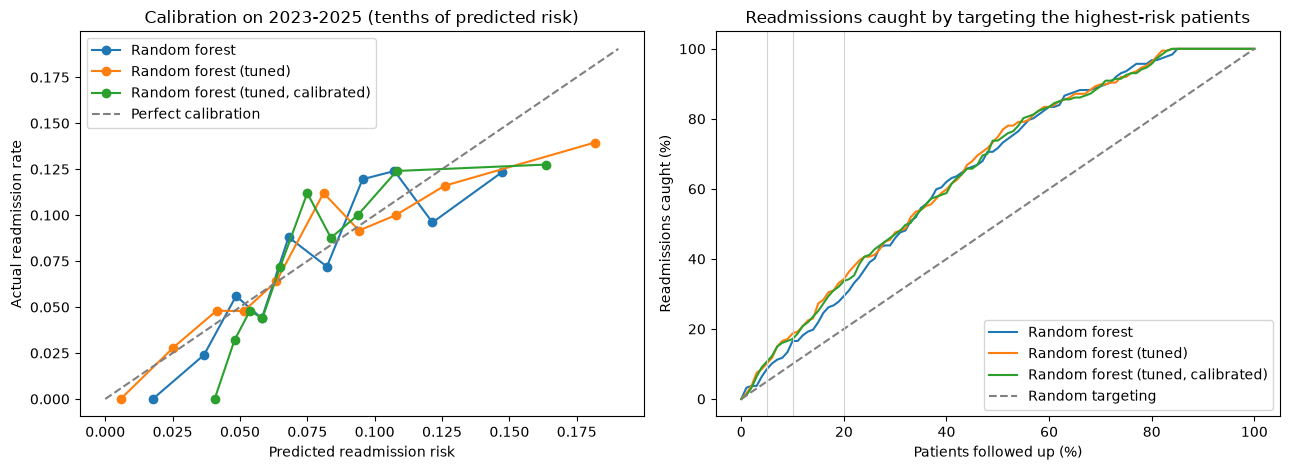

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Calibration: predicted risk vs actual readmission rate, by tenth of predicted risk
for name in CHART_MODELS:
    p = p_test[name]
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax1.plot(mean_pred, frac_pos, marker="o", label=name)
lim = max(ax1.get_xlim()[1], ax1.get_ylim()[1])
ax1.plot([0, lim], [0, lim], ls="--", color="grey", label="Perfect calibration")
ax1.set_title("Calibration on 2023-2025 (tenths of predicted risk)")
ax1.set_xlabel("Predicted readmission risk"); ax1.set_ylabel("Actual readmission rate")
ax1.legend()

# Capture curve: share of readmissions caught vs share of patients followed up
shares = np.linspace(0, 1, 101)
for name in CHART_MODELS:
    p = p_test[name]
    order = np.argsort(-p)
    caught = np.concatenate([[0], np.cumsum(y_test.to_numpy()[order])]) / y_test.sum()
    idx = (shares * len(p)).round().astype(int)
    ax2.plot(100 * shares, 100 * caught[idx], label=name)
ax2.plot([0, 100], [0, 100], ls="--", color="grey", label="Random targeting")
for share in TARGET_SHARES:
    ax2.axvline(100 * share, color="lightgrey", lw=0.8)
ax2.set_title("Readmissions caught by targeting the highest-risk patients")
ax2.set_xlabel("Patients followed up (%)"); ax2.set_ylabel("Readmissions caught (%)")
ax2.legend()
plt.tight_layout(); plt.show()

**Interpretation:** Fine-tuning fixed most of the calibration problem seen with the untuned logistic regression, whose riskiest tenth was predicted at about 17% but readmitted at about 11.5%. For the tuned and calibrated random forest (green), the middle of the risk range tracks the diagonal closely, and the riskiest tenth is predicted at about 16.5% against an actual rate of about 12.5%, so the top end is still somewhat overconfident but much less so. Calibration also squeezes the scores into a narrower range, from about 4% to 16.5%, so the lowest-risk tenth is predicted at about 4% even though none of those patients were readmitted. The capture curves (right) show that tuning helps most at the top of the list: the tuned versions catch more readmissions than the default random forest in the first 20 to 30% of patients, which is where follow-up would actually be targeted.

For the counterfactuals, this means the scores are good for **ranking** patients, and good enough for **totals**. To avoid carrying the remaining overconfidence into the savings estimate, the counterfactuals should use the actual readmission rate observed in each risk tenth alongside the predicted risk.

## 8. What drives the risk?
**Permutation importance** shuffles one feature at a time on the test years and measures how much the
champion's AUC drops. A big drop means the model relies on that feature. It works the same way for every
model type, so it is the main explanation. The tuned logistic regression coefficients follow as a
direction check: whether each feature raises or lowers risk.

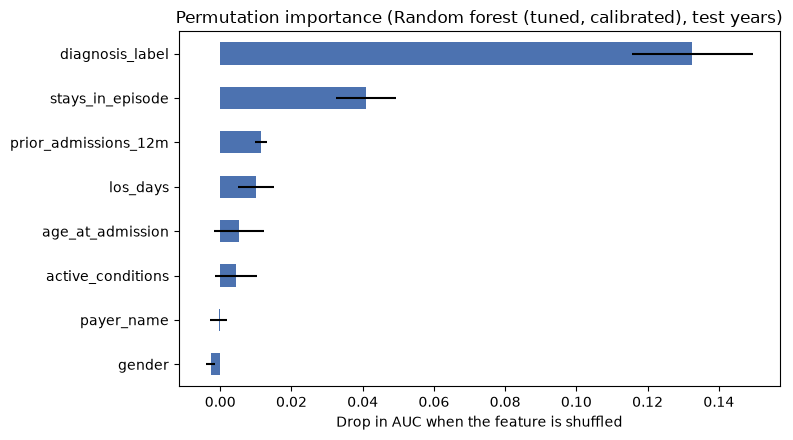

,feature,auc_drop,std
7,diagnosis_label,0.1325,0.0170
2,stays_in_episode,0.0410,0.0085
3,prior_admissions_12m,0.0114,0.0016
1,los_days,0.0100,0.0051
0,age_at_admission,0.0053,0.0070
4,active_conditions,0.0045,0.0060
6,payer_name,-0.0005,0.0023
5,gender,-0.0027,0.0013


In [17]:
importance = permutation_importance(winner, X_test[FEATURES_FINAL], y_test, scoring="roc_auc",
                                    n_repeats=20, random_state=SEED)
imp = (pd.DataFrame({"feature": FEATURES_FINAL,
                     "auc_drop": importance.importances_mean,
                     "std": importance.importances_std})
         .sort_values("auc_drop"))

imp.plot.barh(x="feature", y="auc_drop", xerr="std", legend=False, figsize=(8, 4.5), color="#4C72B0")
plt.title(f"Permutation importance ({winner_name}, test years)")
plt.xlabel("Drop in AUC when the feature is shuffled"); plt.ylabel("")
plt.tight_layout(); plt.show()
imp.sort_values("auc_drop", ascending=False).round(4)

**Interpretation:** The champion still relies most on the cardiac condition: shuffling it drops the AUC by 0.133. But unlike the logistic regression, the random forest also draws on other features. Stays in the episode is a clear second (0.041), and prior admissions (0.011) and length of stay (0.010) both add real signal; age and active conditions add a little, with error bars that overlap zero. Payer and gender add nothing, and gender comes out slightly negative. This wider use of features is why the tuned forest beats the linear model: it can pick up combinations, such as a longer stay on one particular pathway, that a single coefficient per feature cannot express. Payer and gender are candidates to drop in a future version.

In [18]:
# The tuned logistic regression (before calibration) shows the direction of each effect;
# sigmoid calibration rescales the scores but does not change these directions
best_lr = lr_tuned
coef = pd.DataFrame({
    "feature": best_lr.named_steps["prep"].get_feature_names_out(),
    "coefficient": best_lr.named_steps["model"].coef_[0],
})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef["feature"] = coef["feature"].str.replace("num__", "").str.replace("cat__", "")

# Numeric features are standardised, so their odds ratio is per one standard deviation
coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).head(15).round(3)

,feature,coefficient,odds_ratio
17,diagnosis_label_Acute ST segment elevation myo...,-3.589,0.028
16,diagnosis_label_Abnormal findings diagnostic i...,1.279,3.592
23,diagnosis_label_Preinfarction syndrome,-1.166,0.312
19,diagnosis_label_Aortic valve regurgitation,1.113,3.044
18,diagnosis_label_Acute non-ST segment elevation...,-1.008,0.365
20,diagnosis_label_Aortic valve stenosis,0.746,2.109
22,diagnosis_label_History of coronary artery byp...,0.663,1.940
6,payer_name_Aetna,-0.521,0.594
21,diagnosis_label_Chronic congestive heart failure,-0.520,0.594
2,stays_in_episode,-0.445,0.641


**Interpretation:** These coefficients come from the tuned logistic regression, not the champion, and serve as a direction check, since a random forest has no single number per feature. The directions match the earlier run. Compared with the average condition, abnormal heart imaging (odds ratio 3.6), aortic valve regurgitation (3.0), aortic valve stenosis (2.1) and bypass surgery history (1.9) raise the odds of readmission, while STEMI (0.03), preinfarction syndrome (0.31) and NSTEMI (0.37) lower them. Episodes made of more than one stay are less likely to be followed by a readmission (0.64 per standard deviation), probably because a merged episode already contains the next step of the pathway. Prior admissions slightly lower the odds (0.76 per standard deviation), which matches the flat pattern in Section 2 and is the opposite of real hospitals. Commercial insurers (Aetna, Blue Cross Blue Shield, Cigna, Humana and UnitedHealthcare) have somewhat lower odds than the average payer, although payer adds little to the champion's ranking. Gender no longer appears, because it is now a single column with almost no effect.

## 9. Save the risk scores
The champion's scores for every 2023 to 2025 cardiac index episode go to `mart.cardiac_risk_scores`, so the
counterfactuals notebook and Power BI read the same numbers. Rank 1 is the highest-risk episode, and
`risk_percentile` 1 means the top 1%.

In [19]:
scores = test[["episode_id", "patient_id", "admit_date", "admit_year", "diagnosis_label", "readmitted"]].copy()
scores["risk_score"] = winner.predict_proba(X_test)[:, 1]
scores["risk_rank"] = scores["risk_score"].rank(ascending=False, method="first").astype(int)
scores["risk_percentile"] = np.ceil(100 * scores["risk_rank"] / len(scores)).astype(int)
scores["risk_decile"] = np.ceil(10 * scores["risk_rank"] / len(scores)).astype(int)
scores["model"] = winner_name

with engine.begin() as conn:
    scores.to_sql("cardiac_risk_scores", conn, schema="mart", if_exists="replace", index=False)

q("""
    SELECT COUNT(*) AS episodes, SUM(readmitted) AS readmissions,
           ROUND(AVG(risk_score)::numeric, 4) AS avg_risk, MIN(model) AS model
    FROM mart.cardiac_risk_scores
""")

,episodes,readmissions,avg_risk,model
0,2504,187.0,0.079,"Random forest (tuned, calibrated)"


**Interpretation:** The tuned, calibrated random forest's scores for all 2,504 test-period cardiac episodes are saved to `mart.cardiac_risk_scores`, with the 187 actual readmissions alongside and the model name recorded. The average risk score (7.9%) is slightly above the actual readmission rate (7.47%), matching the mild overprediction seen above. These are the scores the counterfactuals notebook will use to target follow-up.

## 10. Summary
**What was built:** a model that scores each cardiac patient's risk of an unplanned readmission within 30 days, trained on 2017 to 2022 and tested on 2023 to 2025, the success test period.

**How the champion was chosen**
* **Round 1, default settings:** four models within 0.03 AUC of each other. Random forest came closest to the baseline (+0.007) but fell short of the +0.01 rule, so logistic regression led.
* **Round 2, equal tuning:** the two front-runners were tuned with Optuna (30 trials each) after dropping the calendar features. Re-scored on fresh folds, the tuned random forest beat the tuned logistic regression by +0.022 AUC and became the **champion**, then was calibrated with Platt scaling.
* The test years were used only after the choice was made, and they confirmed it: the champion has the best test AUC of every model.

**What was found**
* **The champion ranks patients moderately well.** Test AUC is 0.666. Following up the riskiest 5% finds readmissions about 2.2 times as often as untargeted follow-up; the riskiest 10% about 1.7 times. The riskiest 20% catches 33.7% of all readmissions, up from 28.3% with the first-round model.
* **The cardiac condition drives most of the risk.** Valve disease, bypass surgery history and abnormal heart imaging carry the highest risk; acute heart attacks the lowest. The forest also uses stays in the episode, prior admissions and length of stay.
* **Patient history matters far less than in real hospitals.** Prior admissions and active conditions add little, and older patients are readmitted less often, because Synthea generates readmissions from care pathways rather than patient history. This caps how well any model can do on this data.
* **Calibration is good enough to use, with care.** Total readmissions are predicted within about 6%, and the middle of the risk range is well calibrated. The riskiest tenth is still somewhat overconfident (about 16.5% predicted against 12.5% actual).

**What the counterfactuals take from this**
* The risk ranking in `mart.cardiac_risk_scores` decides who gets follow-up first.
* Readmissions avoided are estimated from the **actual readmission rate in each risk tenth**, with the predicted risk as a cross-check, so the remaining overconfidence at the top does not inflate the savings.

**Possible improvements for a later version**
* Drop payer and gender, which add nothing to the champion.
* Add history features the model cannot see yet, such as days since the last discharge or a previous readmission.